# XAI Synthesis: What the Models Look At, Across Models and Methods

Each model notebook explains one model. This notebook puts the explanations side by side to answer three questions that no single notebook can:

1. **Across models:** do the six models rely on the same words, and how much of their reasoning rests on source artefacts rather than on writing style or content? (Section 3)
2. **Across methods:** where do LIME and SHAP agree, where do they disagree, and why? (Section 4)
3. **Across outcomes:** what do the explanations of correct and wrong predictions look like, and what does that say about why the explained model (the RBF SVM) fails? (Section 5)

**Shared set-up.** Every model is trained exactly as in its own notebook (same cleaned data, preprocessing, TF-IDF, split and `RANDOM_STATE = 42`). LIME is run with the same settings for every model (1,000 samples, top 10 words, explaining the fake class), so the explanations are comparable. Figures go to `figures/`, numbers to `results/xai_synthesis_results.json`.

**Word categories.** To summarise thousands of explanations, words are grouped into four categories fixed *before* this analysis, from the team's own earlier findings:

| Category | Words | Source |
|---|---|---|
| Source and format artefacts | reuters, via, image, images, featured, getty, com, http, www, pic, twitter, wire, read, video, watch | fingerprint list, baseline notebook Section 8.1 |
| Wire-service conventions | said, told, minister, government, spokesman, presidential, representative, nov, monday to sunday | `dataset_eda.ipynb` Section 9 and baseline Section 8 ("Reuters house style") |
| Partisan and conversational style | just, like, know, don, right, fact, gop, hillary, mr, breaking, even | `dataset_eda.ipynb` Section 9 and baseline Section 8 ("fake-site style") |
| Other (topic and content) | every other word | — |

## 1. Setup

In [1]:
import os, sys, json, time, warnings
if not os.path.exists("preprocessing.py"):
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import joblib
import shap
from IPython.display import display
from scipy.stats import spearmanr
from lime.lime_text import LimeTextExplainer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from preprocessing import preprocess_text, get_split_tfidf, select_top_k_terms, RANDOM_STATE

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
FIG_DIR, RES_DIR = "figures", "results"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)
RESULTS = {"random_state": RANDOM_STATE}

/home/claude/venv314/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.1 Data and the Six Models

Same pipeline and hyperparameters as the model notebooks. The SVM is loaded from the cache written by `xai_evaluation.ipynb` when it exists (it takes about 15 minutes to train), otherwise trained and cached. XGBoost is trained and explained on dense arrays, as in its notebook.

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()
vocab = tfidf.vocabulary_
test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true = y_test.to_numpy()

t0 = time.time()
lr = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000).fit(X_train, y_train)
dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=5,
                            random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
lgbm = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, max_depth=4, min_child_samples=50,
                      random_state=RANDOM_STATE, n_jobs=-1, verbose=-1).fit(X_train, y_train)
xgb = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, min_child_weight=10, tree_method="hist",
                    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train.toarray().astype(np.float32), y_train)
SVM_CACHE = "Model/XAI Evaluation/svm_rbf.joblib"
if os.path.exists(SVM_CACHE):
    svm_model = joblib.load(SVM_CACHE)
else:
    svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE).fit(X_train, y_train)
    joblib.dump(svm_model, SVM_CACHE)
print(f"Models ready in {time.time() - t0:.0f} s")

Models ready in 181 s


In [3]:
# Exact RBF-SVM decision value from the fitted parameters (fast; checked against scikit-learn below)
_SV = sp.csr_matrix(svm_model.support_vectors_); _SVT = _SV.T.tocsr()
_sv_sq = np.asarray(_SV.multiply(_SV).sum(axis=1)).ravel()
_dual = np.asarray(sp.csr_matrix(svm_model.dual_coef_).todense()).ravel()
_b, _gamma = svm_model.intercept_[0], svm_model._gamma
def svm_decision(X):
    X = sp.csr_matrix(X)
    x_sq = np.asarray(X.multiply(X).sum(axis=1)).ravel()
    return np.exp(-_gamma * (x_sq[:, None] + _sv_sq[None, :] - 2 * (X @ _SVT).toarray())) @ _dual + _b
svm_score = svm_model.decision_function(X_test)
assert np.abs(svm_decision(X_test) - svm_score).max() < 1e-8
svm_pred = (svm_score > 0).astype(int)

def two_col(p):
    return np.column_stack([1 - p, p])
# text -> class scores, one function per model, as LIME needs them (SVM: sigmoid of the decision value, as in SVM.ipynb)
PREDICT = {
    "Logistic regression": lambda t: lr.predict_proba(tfidf.transform(t)),
    "Decision tree": lambda t: dt.predict_proba(tfidf.transform(t)),
    "Random Forest": lambda t: rf.predict_proba(tfidf.transform(t)),
    "LightGBM": lambda t: lgbm.predict_proba(tfidf.transform(t)),
    "XGBoost": lambda t: xgb.predict_proba(tfidf.transform(t).toarray().astype(np.float32)),
    "SVM (RBF)": lambda t: two_col(1 / (1 + np.exp(-svm_decision(tfidf.transform(t))))),
}
MODELS = list(PREDICT)

ARTEFACT = {"reuters", "via", "image", "images", "featured", "getty", "com", "http", "www", "pic", "twitter", "wire", "read", "video", "watch"}
WIRE = {"said", "told", "minister", "government", "spokesman", "presidential", "representative", "nov",
        "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"}
PARTISAN = {"just", "like", "know", "don", "right", "fact", "gop", "hillary", "mr", "breaking", "even"}
CATS = ["Source/format artefacts", "Wire-service conventions", "Partisan/conversational", "Other (topic/content)"]
def category(w):
    return CATS[0] if w in ARTEFACT else CATS[1] if w in WIRE else CATS[2] if w in PARTISAN else CATS[3]

## 2. Explanation Sample

200 test articles (100 fake, 100 real, drawn with the project seed). Every model is explained on the same 200 articles with the same LIME settings, so differences between models come from the models, not from the articles or the explainer.

In [4]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = np.concatenate([rng.choice(np.where(y_true == c)[0], 100, replace=False) for c in (1, 0)])

t0 = time.time()
rows = []
for name in MODELS:
    explainer = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
    for i in sample_idx:
        exp = explainer.explain_instance(test_text.iloc[i], PREDICT[name], num_features=10, num_samples=1000, labels=(1,))
        for rank, (word, weight) in enumerate(exp.as_list(label=1)):
            rows.append((name, int(i), word, weight, rank))
lime_all = pd.DataFrame(rows, columns=["model", "article", "word", "weight", "rank"])
lime_all["category"] = lime_all["word"].map(category)
lime_all["abs_weight"] = lime_all["weight"].abs()
print(f"LIME explanations for 6 models x 200 articles in {time.time() - t0:.0f} s")

LIME explanations for 6 models x 200 articles in 222 s


## 3. Across Models: Shared Anchors, Different Reliance

### 3.1 Top Words per Model

Global importance of a word = its mean |LIME weight| over the 200 articles (0 where it is not in an article's top 10); the sign shows the direction it pushes on average (+ fake, − real). LIME weights are changes in each model's score, so they are compared *within* a model; Section 3.2 compares models through shares.

In [5]:
n_art = len(sample_idx)
glob = (lime_all.groupby(["model", "word"])
        .agg(importance=("abs_weight", lambda s: s.sum() / n_art), direction=("weight", "mean"))
        .reset_index())
top_table = {}
for m in MODELS:
    g = glob[glob.model == m].nlargest(10, "importance")
    top_table[m] = [f"{w} ({'+' if d > 0 else '−'})" for w, d in zip(g.word, g.direction)]
top_table = pd.DataFrame(top_table, index=range(1, 11))
display(top_table)

anchors = set.intersection(*[set(glob[glob.model == m].nlargest(15, "importance").word) for m in MODELS])
print("Words in the top 15 of all six models:", sorted(anchors))
for w in sorted(anchors):
    dirs = {m: float(glob[(glob.model == m) & (glob.word == w)].direction.iloc[0]) for m in MODELS}
    print(f"  {w:8s} pushes {'fake' if np.mean(list(dirs.values())) > 0 else 'real'} in {sum(np.sign(v) == np.sign(np.mean(list(dirs.values()))) for v in dirs.values())} of 6 models")
RESULTS["anchors_top15_all_models"] = sorted(anchors)

,Logistic regression,Decision tree,Random Forest,LightGBM,XGBoost,SVM (RBF)
1,said (−),said (−),said (−),said (−),said (−),said (−)
2,via (+),via (+),image (+),via (+),via (+),via (+)
3,video (+),video (+),via (+),video (+),image (+),image (+)
4,image (+),reuters (−),video (+),image (+),video (+),video (+)
5,hillary (+),qatar (+),featured (+),read (+),read (+),hillary (+)
6,mr (+),pope (−),getty (+),hillary (+),hillary (+),gop (+)
7,obama (+),egypt (+),watch (+),minister (−),minister (−),read (+)
8,thursday (−),colombia (−),com (+),reuters (−),reuters (−),republican (−)
9,friday (−),guest (+),know (+),watch (+),watch (+),wednesday (−)
10,house (−),image (+),minister (−),thursday (−),thursday (−),thursday (−)


Words in the top 15 of all six models: [np.str_('image'), np.str_('said'), np.str_('via'), np.str_('video')]
  image    pushes fake in 6 of 6 models
  said     pushes real in 6 of 6 models
  via      pushes fake in 6 of 6 models
  video    pushes fake in 6 of 6 models


All six models put the same four words in their top 15: **said** pushes toward real and **via**, **image** and **video** push toward fake, in every model. Beyond these anchors the lists split by model family. Logistic regression and the SVM add partisan naming (hillary, gop, obama, mr) and weekday attribution; LightGBM and XGBoost add more page furniture (read, watch) and reuters; the Random Forest adds the rest of the photo-credit line (featured, getty, com). The decision tree's list below rank 4 is noise: words such as qatar or pope get LIME weights near 0.001, because the tree only uses five terms.

### 3.2 What Each Model Relies On: Category Shares

Share of each model's total |LIME| weight that falls on each word category, the share carried by its five most important words (concentration), and the share carried by the four photo-credit words (image, via, featured, getty), the group whose grouped PFI the model notebooks report.

In [6]:
share = lime_all.groupby(["model", "category"])["abs_weight"].sum().unstack().reindex(columns=CATS).fillna(0)
share = share.div(share.sum(axis=1), axis=0).loc[MODELS]
concentration = pd.Series({m: glob[glob.model == m].nlargest(5, "importance").importance.sum() / glob[glob.model == m].importance.sum()
                           for m in MODELS}, name="Top-5 words' share")
photo_credit = {"image", "via", "featured", "getty"}
pc_share = (lime_all[lime_all.word.isin(photo_credit)].groupby("model")["abs_weight"].sum()
            / lime_all.groupby("model")["abs_weight"].sum()).loc[MODELS].rename("Photo-credit words' share")
display(pd.concat([share, concentration, pc_share], axis=1).round(3))
RESULTS["category_share_by_model"] = share.round(3).to_dict(orient="index")
RESULTS["photo_credit_share_by_model"] = pc_share.round(3).to_dict()
RESULTS["top5_concentration"] = concentration.round(3).to_dict()

,Source/format artefacts,Wire-service conventions,Partisan/conversational,Other (topic/content),Top-5 words' share,Photo-credit words' share
Logistic regression,0.141,0.325,0.071,0.462,0.328,0.063
Decision tree,0.384,0.518,0.001,0.098,0.902,0.251
Random Forest,0.354,0.300,0.081,0.265,0.406,0.196
LightGBM,0.332,0.376,0.078,0.214,0.479,0.160
XGBoost,0.342,0.370,0.081,0.207,0.492,0.169
SVM (RBF),0.201,0.281,0.072,0.446,0.326,0.098


The models differ most in how much they lean on source artefacts. In the three tree ensembles, 33–35% of LIME's weight falls on the 15 artefact words (38% in the depth-3 tree), against 20% for the SVM and 14% for logistic regression. The SVM and the baseline instead put 45–46% of their weight on topic and content words outside the three style categories, and spread it widely: their five most important words carry 33% of the weight, against 41–49% for the ensembles and 90% for the tree. The ensembles' accuracy therefore rests more on the fake sites' page layout, the SVM's on many small content and style cues, which is also why permuting any single word rarely changes an SVM prediction (`SVM.ipynb`, Section 9.1).

Attribution is not the same as dependence. The four photo-credit words carry a slightly larger share of LIME weight in the Random Forest (20%) than in LightGBM and XGBoost (16–17%), yet shuffling them costs the boosted models about three times as much Fake-class recall (grouped PFI 0.061 and 0.058 vs 0.019; Section 9.1 of each notebook). The forest uses the photo credit as much, but has other words to fall back on when it is gone.

### 3.3 How Similar Are the Models' Explanations?

Spearman correlation of global word importance between two models, over the union of their 20 most important words. High values mean the two models rank the same words as important.

In [7]:
P = glob.pivot(index="word", columns="model", values="importance").fillna(0)
sim = pd.DataFrame(index=MODELS, columns=MODELS, dtype=float)
for a in MODELS:
    for b in MODELS:
        union = list(set(glob[glob.model == a].nlargest(20, "importance").word) | set(glob[glob.model == b].nlargest(20, "importance").word))
        sim.loc[a, b] = spearmanr(P.loc[union, a], P.loc[union, b]).correlation
display(sim.round(2))
RESULTS["model_similarity_spearman"] = sim.round(2).to_dict(orient="index")

,Logistic regression,Decision tree,Random Forest,LightGBM,XGBoost,SVM (RBF)
Logistic regression,1.00,-0.21,-0.00,0.20,0.19,0.69
Decision tree,-0.21,1.00,-0.17,-0.16,-0.16,-0.18
Random Forest,-0.00,-0.17,1.00,0.56,0.57,0.17
LightGBM,0.20,-0.16,0.56,1.00,0.95,0.32
XGBoost,0.19,-0.16,0.57,0.95,1.00,0.36
SVM (RBF),0.69,-0.18,0.17,0.32,0.36,1.00


Explanation similarity follows model family, not accuracy. The SVM's word ranking is closest to logistic regression's (ρ = 0.69), consistent with the almost straight ALE and ICE curves in `SVM.ipynb`; LightGBM and XGBoost are almost interchangeable (ρ = 0.95) and moderately close to the Random Forest (0.56–0.57); the decision tree correlates with nothing, because its explanation is five words. Models with almost the same accuracy (SVM 0.984, XGBoost 0.980) reach it through different evidence (ρ = 0.36), so accuracy alone cannot tell a reviewer what a flag rests on.

## 4. Across Methods: Where LIME and SHAP Agree, and Why They Differ

LIME and the KernelSHAP set-up used for the SVM both measure what happens when a word is **removed** from the article. TreeSHAP (and SHAP for linear models) instead compares the article with the **average training article**, so a word that is *absent* also gets credit or blame. We measure (a) how much of SHAP's attribution goes to absent words and (b) how well the two methods agree on the words that are present.

In [8]:
# (a) share of SHAP attribution mass on words that are ABSENT from the article (same 200 articles)
Xs = X_test[sample_idx].toarray()
present = Xs > 0
absence = {}
for name, model, X_in in [("Decision tree", dt, Xs), ("Random Forest", rf, Xs), ("LightGBM", lgbm, Xs), ("XGBoost", xgb, Xs.astype(np.float32))]:
    v = shap.TreeExplainer(model).shap_values(X_in, check_additivity=False)
    v = v[1] if isinstance(v, list) else (v[:, :, 1] if np.ndim(v) == 3 else v)
    absence[name] = np.abs(v[~present]).sum() / np.abs(v).sum()
    if name == "LightGBM":
        lgbm_shap = v
mu = np.asarray(X_train.mean(axis=0)).ravel()
v_lin = lr.coef_[0] * (Xs - mu)                     # exact (interventional) SHAP for a linear model
absence["Logistic regression (linear SHAP)"] = np.abs(v_lin[~present]).sum() / np.abs(v_lin).sum()
absence = pd.Series(absence, name="share of |SHAP| on absent words")
display(absence.round(3))
absent_terms = pd.Series(np.where(~present, np.abs(lgbm_shap), 0).sum(axis=0), index=feature_names)
absent_terms = (absent_terms / np.abs(lgbm_shap).sum()).nlargest(6)
print("LightGBM: absent words carrying the most attribution (share of all |SHAP|):")
print(absent_terms.round(3).to_string())
RESULTS["shap_absence_share"] = absence.round(3).to_dict()
RESULTS["lgbm_top_absent_terms"] = absent_terms.round(3).to_dict()

Decision tree                        0.450
Random Forest                        0.477
LightGBM                             0.460
XGBoost                              0.442
Logistic regression (linear SHAP)    0.490
Name: share of |SHAP| on absent words, dtype: float64

LightGBM: absent words carrying the most attribution (share of all |SHAP|):
via         0.056
said        0.038
image       0.034
video       0.028
featured    0.023
reuters     0.015


Between 44% and 49% of the SHAP attribution goes to words the article does **not** contain, for every tree model and for the linear baseline. For LightGBM the largest of these are the missing photo-credit words and a missing "said" (via 5.6% of all attribution, said 3.8%, image 3.4%, video 2.8%). Nearly half of what TreeSHAP reports is therefore evidence of absence ("this article looks real partly because it has no photo credit"). LIME, and the KernelSHAP set-up used for the SVM, only remove words that are present, so they cannot show this half of the reasoning; a reviewer who sees highlighted words sees only the evidence of presence.

In [9]:
# (b) agreement on PRESENT words, 100 of the 200 articles (50 fake, 50 real)
top_idx, top_terms, _ = select_top_k_terms(X_train, y_train, feature_names, k=30, method="chi2")
def kernel_shap_topk(x_row, nsamples=500, seed=RANDOM_STATE):
    def f(Z):
        full = np.tile(x_row, (Z.shape[0], 1)); full[:, top_idx] = Z
        return svm_decision(full)
    np.random.seed(seed)
    ex = shap.KernelExplainer(f, np.zeros((1, len(top_idx))))
    return ex.shap_values(x_row[top_idx].reshape(1, -1), nsamples=nsamples, silent=True)[0]

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else np.nan

sub = np.concatenate([sample_idx[:50], sample_idx[100:150]])
lgbm_pos = {i: k for k, i in enumerate(sample_idx)}
explainer = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
t0, rows = time.time(), []
for i in sub:
    text = test_text.iloc[i]
    n_words = len(set(text.split()))
    # SVM: LIME vs KernelSHAP on the top-30 terms present in the article
    lw = dict(explainer.explain_instance(text, PREDICT["SVM (RBF)"], num_features=n_words, num_samples=1000, labels=(1,)).as_list(label=1))
    ks = kernel_shap_topk(Xs[lgbm_pos[i]])
    pres = [j for j in range(len(top_idx)) if Xs[lgbm_pos[i], top_idx[j]] > 0 and top_terms[j] in lw]
    if len(pres) >= 3:
        a, b = [lw[top_terms[j]] for j in pres], [ks[j] for j in pres]
        rows.append({"pair": "SVM: LIME vs KernelSHAP", "spearman": spearmanr(a, b).correlation,
                     "sign_agreement": np.mean(np.sign(a) == np.sign(b)),
                     "same_top_word": np.argmax(np.abs(a)) == np.argmax(np.abs(b)),
                     "top3_jaccard": jaccard([top_terms[pres[k]] for k in np.argsort(-np.abs(a))[:3]],
                                             [top_terms[pres[k]] for k in np.argsort(-np.abs(b))[:3]])})
    # LightGBM: LIME vs TreeSHAP on all words present in the article
    lw = dict(explainer.explain_instance(text, PREDICT["LightGBM"], num_features=n_words, num_samples=1000, labels=(1,)).as_list(label=1))
    words = [w for w in set(text.split()) if w in vocab and w in lw]
    a, b = np.array([lw[w] for w in words]), np.array([lgbm_shap[lgbm_pos[i], vocab[w]] for w in words])
    nz = np.abs(b) > 1e-9
    rows.append({"pair": "LightGBM: LIME vs TreeSHAP", "spearman": spearmanr(a, b).correlation,
                 "sign_agreement": np.mean(np.sign(a[nz]) == np.sign(b[nz])) if nz.any() else np.nan,
                 "same_top_word": np.argmax(np.abs(a)) == np.argmax(np.abs(b)),
                 "top3_jaccard": jaccard([words[k] for k in np.argsort(-np.abs(a))[:3]], [words[k] for k in np.argsort(-np.abs(b))[:3]]),
                 "share_present_words_with_zero_shap": 1 - nz.mean()})
agree = pd.DataFrame(rows)
summary = agree.groupby("pair").agg(["mean", "count"]).round(3)
display(summary)
print(f"done in {time.time() - t0:.0f} s")
RESULTS["lime_vs_shap"] = {p: g.drop(columns="pair").mean().round(3).to_dict() | {"n_articles": int(len(g))} for p, g in agree.groupby("pair")}

spearman       sign_agreement       same_top_word       top3_jaccard       share_present_words_with_zero_shap      
                               mean count           mean count          mean count         mean count                               mean count
pair                                                                                                                                          
LightGBM: LIME vs TreeSHAP    0.307   100          0.661   100          0.62   100        0.722   100                              0.688   100
SVM: LIME vs KernelSHAP       0.961    75          0.941    75          1.00    75        0.953    75                                NaN     0

done in 62 s


Where both methods measure the same thing, they agree almost perfectly. For the SVM, LIME and KernelSHAP rank the top-30 terms present in an article with a mean Spearman correlation of 0.96, pick the same top word in all 75 articles that contain at least three of these terms, and give 94% of terms the same sign. For LightGBM the agreement over all present words is weak (ρ = 0.31, same sign 66%, same top word 62%), although the top three words still overlap well (Jaccard 0.72). The main reason is structural, not noise: 69% of the words in an article are never used by LightGBM's trees and get exactly zero TreeSHAP, while LIME's word deletion re-normalises the TF-IDF vector and gives every word some weight. The two methods answer different questions: LIME asks "what if this word were deleted?", TreeSHAP "how does this article differ from the average training article?". Either one alone gives a partial account.

## 5. Across Outcomes: Explaining the SVM's Right and Wrong Decisions

The explained model is the RBF SVM. We explain all of its errors on the test set (every missed fake and every wrongly flagged real article) and 100 random correct predictions of each kind, with the same LIME settings, and look at the words that **support** the decision it made (positive weight toward the predicted class) and the words that **oppose** it.

In [10]:
rng = np.random.RandomState(RANDOM_STATE + 6)
groups = {
    "TP (fake, flagged)": rng.choice(np.where((y_true == 1) & (svm_pred == 1))[0], 100, replace=False),
    "FP (real, flagged)": np.where((y_true == 0) & (svm_pred == 1))[0],
    "TN (real, cleared)": rng.choice(np.where((y_true == 0) & (svm_pred == 0))[0], 100, replace=False),
    "FN (fake, missed)": np.where((y_true == 1) & (svm_pred == 0))[0],
}
explainer = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
t0, rows = time.time(), []
for g, ids in groups.items():
    for i in ids:
        sgn = 1 if svm_pred[i] == 1 else -1
        for rank, (word, weight) in enumerate(explainer.explain_instance(test_text.iloc[i], PREDICT["SVM (RBF)"], num_features=10,
                                                                         num_samples=1000, labels=(1,)).as_list(label=1)):
            rows.append((g, int(i), word, weight, sgn * weight, rank))
out = pd.DataFrame(rows, columns=["group", "article", "word", "weight", "support", "rank"])
out["category"] = out["word"].map(category)
print(f"{sum(len(v) for v in groups.values())} articles explained in {time.time() - t0:.0f} s")
print("Median |decision value| by group:", {g: round(float(np.median(np.abs(svm_score[ids]))), 2) for g, ids in groups.items()})

326 articles explained in 139 s
Median |decision value| by group: {'TP (fake, flagged)': 1.42, 'FP (real, flagged)': 0.25, 'TN (real, cleared)': 1.29, 'FN (fake, missed)': 0.16}


In [11]:
order = list(groups)
sup = out[out.support > 0]
support_share = sup.groupby(["group", "category"])["support"].sum().unstack().reindex(columns=CATS).fillna(0)
support_share = support_share.div(support_share.sum(axis=1), axis=0).loc[order]
print("Share of the SUPPORTING weight by word category:")
display(support_share.round(3))

top3 = sup.sort_values("support", ascending=False).groupby("article").head(3)
freq = {g: (top3[top3.group == g].word.value_counts() / len(groups[g])).head(6).round(2).to_dict() for g in order}
for g in order:
    print(f"{g:20s} most frequent top-3 supporting words (share of articles): {freq[g]}")

has_art = top3.assign(art=top3.category == CATS[0]).groupby(["group", "article"]).art.any().groupby("group").mean().loc[order]
wire_top1 = sup.sort_values("support", ascending=False).groupby("article").head(1)
wire_top1 = (wire_top1.category == CATS[1]).groupby(wire_top1.group).mean().loc[order]
print("\nArticles with an artefact among the top-3 supporting words:", has_art.round(2).to_dict())
print("Articles whose single strongest supporting word is a wire-service convention:", wire_top1.round(2).to_dict())
RESULTS["svm_support_share_by_outcome"] = support_share.round(3).to_dict(orient="index")
RESULTS["svm_top3_word_freq"] = freq
RESULTS["svm_artefact_in_top3"] = has_art.round(3).to_dict()
RESULTS["svm_wire_top1"] = wire_top1.round(3).to_dict()
RESULTS["svm_group_sizes"] = {g: int(len(v)) for g, v in groups.items()}
RESULTS["svm_median_abs_decision"] = {g: round(float(np.median(np.abs(svm_score[ids]))), 2) for g, ids in groups.items()}

Share of the SUPPORTING weight by word category:


category,Source/format artefacts,Wire-service conventions,Partisan/conversational,Other (topic/content)
group,,,,
"TP (fake, flagged)",0.467,0.000,0.166,0.367
"FP (real, flagged)",0.162,0.000,0.148,0.690
"TN (real, cleared)",0.021,0.614,0.000,0.364
"FN (fake, missed)",0.019,0.618,0.000,0.364


TP (fake, flagged)   most frequent top-3 supporting words (share of articles): {np.str_('via'): 0.54, np.str_('image'): 0.36, np.str_('video'): 0.29, np.str_('hillary'): 0.13, np.str_('gop'): 0.13, np.str_('read'): 0.12}
FP (real, flagged)   most frequent top-3 supporting words (share of articles): {np.str_('like'): 0.18, np.str_('obama'): 0.13, np.str_('american'): 0.13, np.str_('even'): 0.13, np.str_('press'): 0.1, np.str_('read'): 0.1}
TN (real, cleared)   most frequent top-3 supporting words (share of articles): {np.str_('said'): 0.89, np.str_('wednesday'): 0.17, np.str_('friday'): 0.16, np.str_('republican'): 0.16, np.str_('tuesday'): 0.14, np.str_('reuters'): 0.1}
FN (fake, missed)    most frequent top-3 supporting words (share of articles): {np.str_('said'): 0.84, np.str_('wednesday'): 0.15, np.str_('tuesday'): 0.1, np.str_('presidential'): 0.09, np.str_('friday'): 0.09, np.str_('thursday'): 0.09}

Articles with an artefact among the top-3 supporting words: {'TP (fake, flagged)'

The explanations of the SVM's correct and wrong decisions separate cleanly.

- **Correct flags rest on page furniture.** An artefact word (most often via, image or video) is among the top three supporting words in 92% of true positives, and artefacts carry 47% of their supporting weight.
- **Wrong flags rest on topic and talk.** Only 28% of false positives have an artefact in their top three; 69% of their supporting weight comes from topic and content words (politicians' names such as obama, "american", "press") and 15% from conversational and partisan words (like, even).
- **Missed fakes look like Reuters.** Wire-service conventions carry 62% of the supporting weight in missed fakes, the same as in correctly cleared real articles (61%); "said" is among the top three words in 84% of missed fakes (89% of real ones), and the single strongest reason is a wire convention in 75% of them.

So the SVM misses fakes that are written like a wire report and wrongly flags real articles that discuss the people, topics and quotes that fake sites write about. Both kinds of error sit close to the boundary (median |decision value| 0.16 and 0.25, against 1.29 and 1.42 for correct decisions).

**Reading rule for the reviewer.** A flag whose highlighted words are page furniture is usually right; a flag that rests on names, topics and quoted speech, with no artefact among its top three words, deserves a fact-check before demotion. The rule is not free: 8% of the sampled correct flags also lack an artefact in their top three, which over all 3,402 correct flags would be roughly 270 extra checks for the 28 false positives it catches.

## Findings in Brief

1. **Shared anchors.** All six models rely on the same four words in the same directions: said (real) and via, image, video (fake).
2. **Different reliance.** Tree ensembles put 33–38% of their LIME weight on source artefacts; the SVM 20% and logistic regression 14%, with 45–46% on topic and content words. Explanation similarity follows model family (SVM ≈ logistic regression, ρ = 0.69; LightGBM ≈ XGBoost, ρ = 0.95), not accuracy.
3. **Absence matters, and only SHAP shows it.** 44–49% of SHAP attribution is on words the article lacks (above all the missing photo credit and a missing "said"). LIME cannot show this.
4. **Methods agree when they ask the same question.** LIME and KernelSHAP agree on the SVM (ρ = 0.96, same top word 100%); LIME and TreeSHAP agree only partly on LightGBM (ρ = 0.31, same top word 62%) because they use different reference points.
5. **Errors have a signature.** Correct SVM flags rest on page furniture (artefact in the top three for 92%); wrong flags rest on topic words and quoted speech (28% with an artefact); missed fakes are explained exactly like real Reuters articles (wire conventions 62% vs 61%).

These are statements about what the models use, not about whether that is right: every pattern above is a property of how Reuters and the fake sites in ISOT write and format articles.

## 6. Figure for the Report

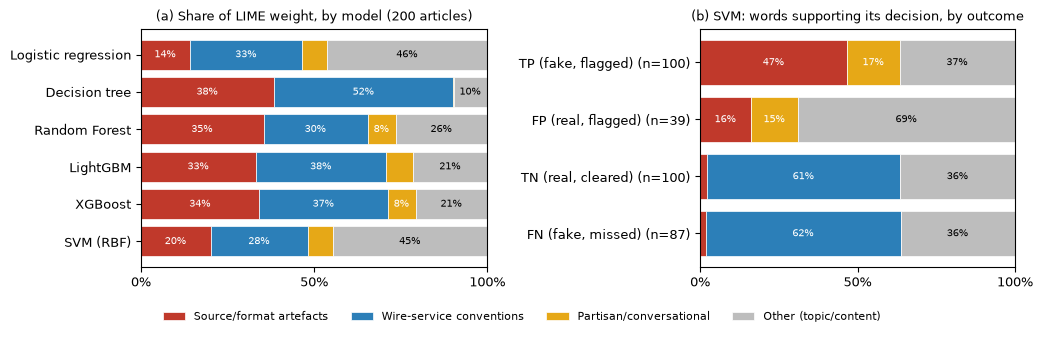

In [12]:
plt.rcParams.update({"font.size": 9})
colors = ["#c0392b", "#2c7fb8", "#e6a817", "#bdbdbd"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3), gridspec_kw={"width_ratios": [1.1, 1]})
for ax, data, title in [(axes[0], share, "(a) Share of LIME weight, by model (200 articles)"),
                        (axes[1], support_share, "(b) SVM: words supporting its decision, by outcome")]:
    left = np.zeros(len(data))
    for c, col in zip(CATS, colors):
        ax.barh(range(len(data)), data[c].values, left=left, color=col, label=c, edgecolor="white", linewidth=0.5)
        for k, (l, v) in enumerate(zip(left, data[c].values)):
            if v >= 0.08:
                ax.text(l + v / 2, k, f"{v:.0%}", ha="center", va="center", fontsize=7.5, color="white" if col != "#bdbdbd" else "black")
        left += data[c].values
    ax.set_yticks(range(len(data))); ax.set_yticklabels(data.index); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(["0%", "50%", "100%"])
    ax.set_title(title, fontsize=9.5)
axes[1].set_yticklabels([f"{g} (n={len(groups[g])})" for g in order])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.savefig(f"{FIG_DIR}/fig_xai_synthesis.png", dpi=300); plt.show()
plt.rcParams.update({"font.size": 10})

## 7. Save All Numbers

In [13]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, np.generic):
        return o.item()
    return o
with open(f"{RES_DIR}/xai_synthesis_results.json", "w") as fh:
    json.dump(to_jsonable(RESULTS), fh, indent=2)
print("Saved", f"{RES_DIR}/xai_synthesis_results.json")

Saved results/xai_synthesis_results.json
